# Team 6 — Anomaly Detection in ECG Signals

## Workshop 1: Supervised Learning

### Project Objective

The objective of this project is to analyze electrocardiogram (ECG) signals
from the MIT-BIH Arrhythmia Database and develop supervised machine learning
models to distinguish normal and abnormal heartbeats.

### Dataset Source

- Dataset: MIT-BIH Arrhythmia Database
- Source: PhysioNet
- Version: 1.0.0
- Number of recordings: 48
- Number of subjects: 47
- Number of ECG channels: 2
- Sampling frequency: 360 Hz

### Initial Workflow

1. Dataset exploration.
2. Signal visualization.
3. Annotation analysis.
4. Feature extraction.
5. Data preparation.
6. Supervised classification.
7. Model evaluation.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ECG data
import wfdb

# File management
from pathlib import Path
from collections import Counter

# Display configuration
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Project paths
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw" / "mitdb"
REPORTS_DIR = PROJECT_DIR / "reports"

print("Libraries imported successfully.")
print("Dataset directory:", DATA_DIR)
print("Dataset directory exists:", DATA_DIR.exists())

Libraries imported successfully.
Dataset directory: c:\Users\user\OneDrive\Documents\MachineLearning\workshop_1\data\raw\mitdb
Dataset directory exists: True


In [2]:
inventory = pd.read_csv(
    REPORTS_DIR / "dataset_inventory.csv"
)

print("Dataset inventory shape:", inventory.shape)

display(inventory.head())

print("\nDataset information:")
display(inventory.describe(include="all"))

Dataset inventory shape: (48, 7)


,record_id,channels,sampling_frequency_hz,samples,duration_seconds,total_annotations,annotation_symbols
0,100,2,360,650000,1805.555556,2274,"{""+"": 1, ""A"": 33, ""N"": 2239, ""V"": 1}"
1,101,2,360,650000,1805.555556,1874,"{""+"": 1, ""A"": 3, ""N"": 1860, ""Q"": 2, ""|"": 4, ""~..."
2,102,2,360,650000,1805.555556,2192,"{""+"": 5, ""/"": 2028, ""N"": 99, ""V"": 4, ""f"": 56}"
3,103,2,360,650000,1805.555556,2091,"{""+"": 1, ""A"": 2, ""N"": 2082, ""~"": 6}"
4,104,2,360,650000,1805.555556,2311,"{""+"": 45, ""/"": 1380, ""N"": 163, ""Q"": 18, ""V"": 2..."



Dataset information:


,record_id,channels,sampling_frequency_hz,samples,duration_seconds,total_annotations,annotation_symbols
count,48.000000,48.0,48.0,48.0,4.800000e+01,48.000000,48
unique,NaN,NaN,NaN,NaN,NaN,NaN,48
top,NaN,NaN,NaN,NaN,NaN,NaN,"{""+"": 1, ""A"": 33, ""N"": 2239, ""V"": 1}"
freq,NaN,NaN,NaN,NaN,NaN,NaN,1
mean,166.229167,2.0,360.0,650000.0,1.805556e+03,2346.812500,NaN
std,53.622494,0.0,0.0,0.0,2.297798e-13,451.689107,NaN
min,100.000000,2.0,360.0,650000.0,1.805556e+03,1519.000000,NaN
25%,112.750000,2.0,360.0,650000.0,1.805556e+03,2061.500000,NaN
50%,200.500000,2.0,360.0,650000.0,1.805556e+03,2299.000000,NaN
75%,215.500000,2.0,360.0,650000.0,1.805556e+03,2650.250000,NaN


Record: 100
Channels: 2
Channel names: ['MLII', 'V5']
Sampling frequency: 360 Hz
Total samples: 650000


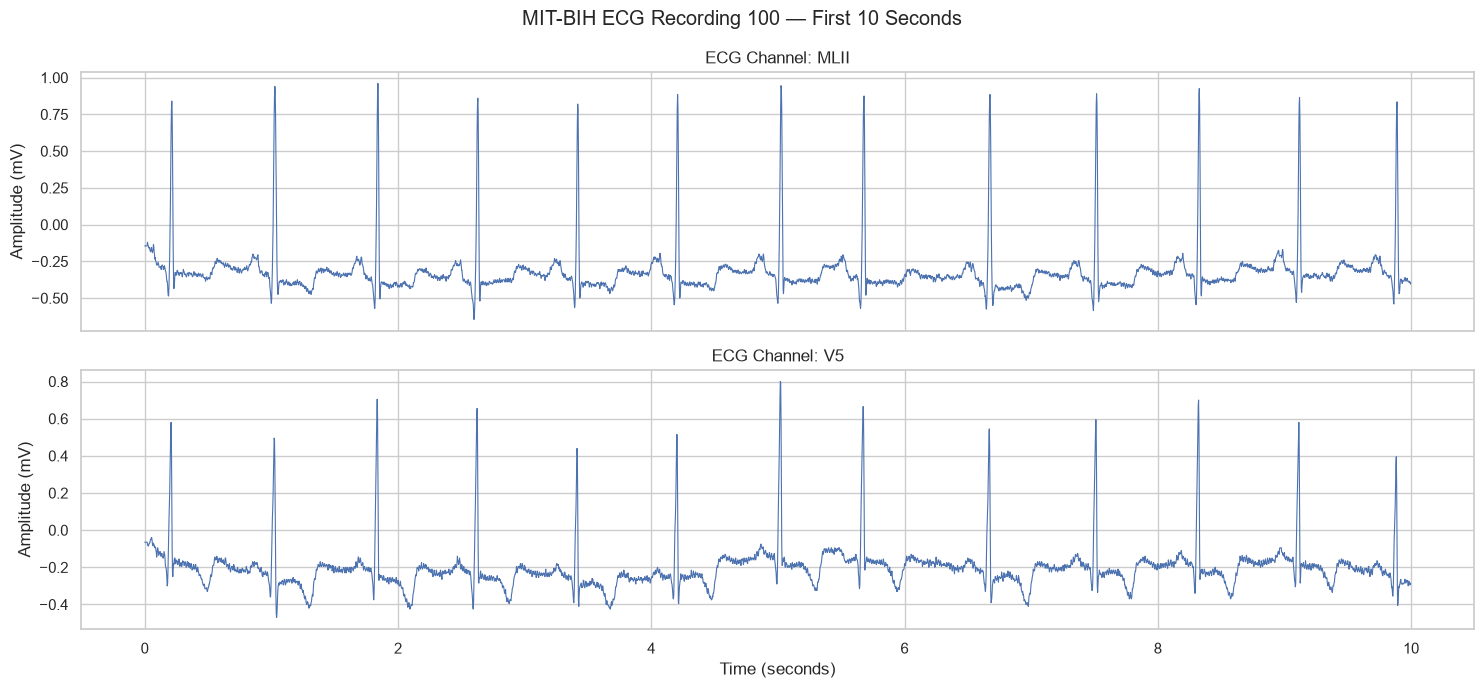

In [3]:
# Select an ECG recording
record_id = "100"

record = wfdb.rdrecord(
    str(DATA_DIR / record_id)
)

# Load reference annotations
annotations = wfdb.rdann(
    str(DATA_DIR / record_id),
    "atr"
)

# Signal information
print("Record:", record_id)
print("Channels:", record.n_sig)
print("Channel names:", record.sig_name)
print("Sampling frequency:", record.fs, "Hz")
print("Total samples:", record.sig_len)

# Select the first 10 seconds
duration_seconds = 10
number_of_samples = int(duration_seconds * record.fs)

time = np.arange(number_of_samples) / record.fs

# Plot ECG signals
fig, axes = plt.subplots(
    record.n_sig,
    1,
    figsize=(15, 7),
    sharex=True
)

for channel in range(record.n_sig):

    axes[channel].plot(
        time,
        record.p_signal[:number_of_samples, channel],
        linewidth=0.8
    )

    axes[channel].set_title(
        f"ECG Channel: {record.sig_name[channel]}"
    )

    axes[channel].set_ylabel("Amplitude (mV)")
    axes[channel].grid(True)

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "MIT-BIH ECG Recording 100 — First 10 Seconds"
)

plt.tight_layout()
plt.show()

In [4]:
# Standard heartbeat annotation symbols
BEAT_SYMBOLS = {
    "N", "L", "R", "B",
    "A", "a", "J", "S",
    "V", "r", "F",
    "e", "j", "E",
    "/", "f", "Q", "?"
}

# Count all annotation symbols in record 100
all_symbols = Counter(annotations.symbol)

print("All annotation symbols:")
display(
    pd.DataFrame(
        all_symbols.items(),
        columns=["Symbol", "Count"]
    ).sort_values("Count", ascending=False)
)

# Keep only heartbeat annotations
beat_annotations = [
    (sample, symbol)
    for sample, symbol in zip(
        annotations.sample,
        annotations.symbol
    )
    if symbol in BEAT_SYMBOLS
]

print("\nHeartbeat annotations:", len(beat_annotations))
print("Other annotations:", len(annotations.sample) - len(beat_annotations))

All annotation symbols:


,Symbol,Count
1,N,2239
2,A,33
0,+,1
3,V,1



Heartbeat annotations: 2273
Other annotations: 1


,Heartbeat Symbol,Count
0,N,2239
1,A,33
2,V,1


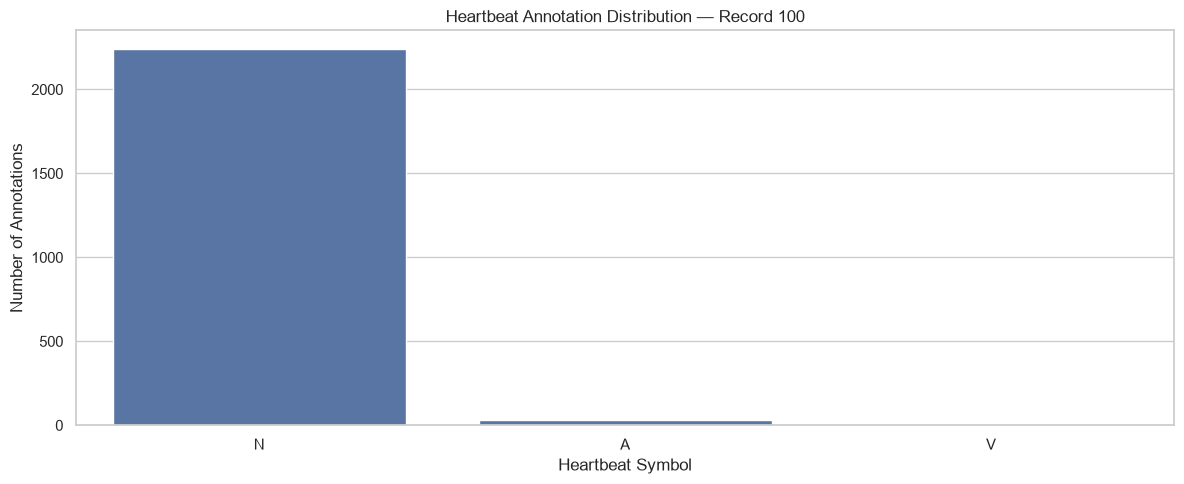

In [5]:
beat_counts = Counter(
    symbol for _, symbol in beat_annotations
)

beat_distribution = pd.DataFrame(
    beat_counts.items(),
    columns=["Heartbeat Symbol", "Count"]
).sort_values(
    "Count",
    ascending=False
)

display(beat_distribution)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=beat_distribution,
    x="Heartbeat Symbol",
    y="Count"
)

plt.title("Heartbeat Annotation Distribution — Record 100")
plt.xlabel("Heartbeat Symbol")
plt.ylabel("Number of Annotations")

plt.tight_layout()
plt.show()

Total heartbeat annotations:
109494

Global heartbeat distribution:


,Heartbeat Symbol,Count
0,N,75052
8,L,8075
11,R,7259
2,V,7130
4,/,7028
1,A,2546
5,f,982
6,F,803
7,j,229
9,a,150


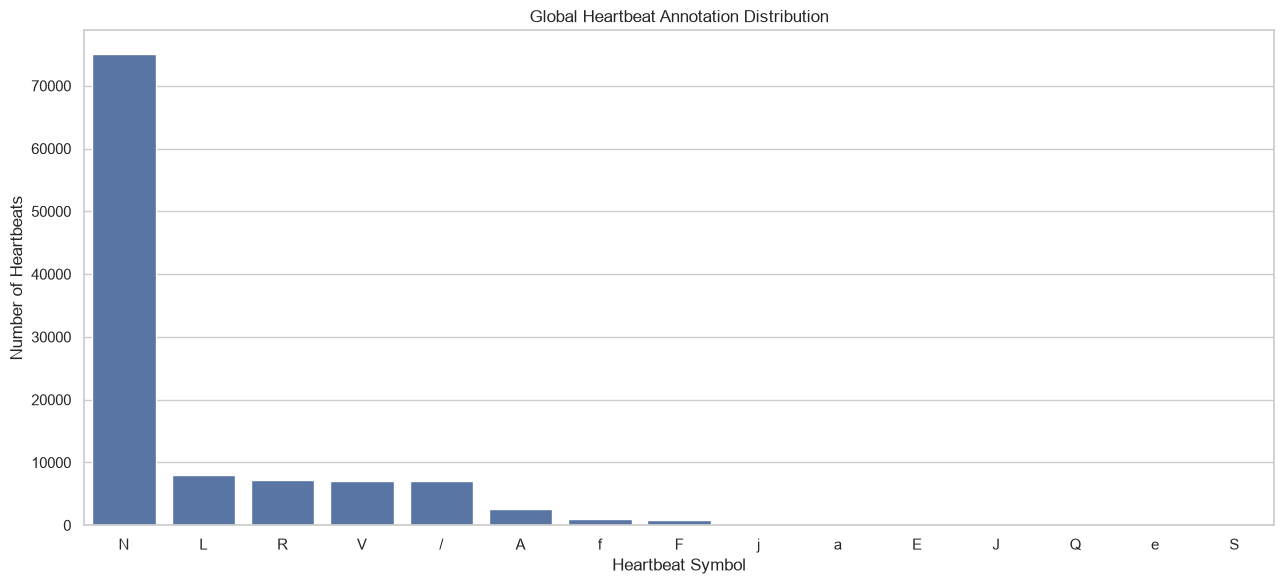

In [6]:
# Analyze heartbeat annotations across all recordings

total_beat_counts = Counter()
total_other_counts = Counter()

for record_id in inventory["record_id"]:

    ann = wfdb.rdann(
        str(DATA_DIR / str(record_id)),
        "atr"
    )

    for symbol in ann.symbol:

        if symbol in BEAT_SYMBOLS:
            total_beat_counts[symbol] += 1
        else:
            total_other_counts[symbol] += 1

# Create global heartbeat distribution
global_distribution = pd.DataFrame(
    total_beat_counts.items(),
    columns=["Heartbeat Symbol", "Count"]
).sort_values(
    "Count",
    ascending=False
)

print("Total heartbeat annotations:")
print(sum(total_beat_counts.values()))

print("\nGlobal heartbeat distribution:")
display(global_distribution)

# Save results
global_distribution.to_csv(
    REPORTS_DIR / "global_heartbeat_distribution.csv",
    index=False
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=global_distribution,
    x="Heartbeat Symbol",
    y="Count"
)

plt.title("Global Heartbeat Annotation Distribution")
plt.xlabel("Heartbeat Symbol")
plt.ylabel("Number of Heartbeats")

plt.tight_layout()
plt.show()

In [7]:
total_beats = sum(total_beat_counts.values())
total_other = sum(total_other_counts.values())

eda_summary = pd.DataFrame({
    "Metric": [
        "Number of recordings",
        "Number of subjects",
        "Total heartbeat annotations",
        "Total non-heartbeat annotations",
        "Number of heartbeat annotation types",
        "Number of non-heartbeat annotation types"
    ],
    "Value": [
        len(inventory),
        47,
        total_beats,
        total_other,
        len(total_beat_counts),
        len(total_other_counts)
    ]
})

display(eda_summary)

eda_summary.to_csv(
    REPORTS_DIR / "eda_summary.csv",
    index=False
)

,Metric,Value
0,Number of recordings,48
1,Number of subjects,47
2,Total heartbeat annotations,109494
3,Total non-heartbeat annotations,3153
4,Number of heartbeat annotation types,15
5,Number of non-heartbeat annotation types,8


# 8. Data Preparation and Feature Extraction

This section converts the annotated ECG recordings into a structured
dataset suitable for supervised machine learning.

Each heartbeat will be represented by a fixed-length ECG signal window.
The annotation symbols will be mapped into normal and abnormal classes.

In [8]:
# Create directory for processed data

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data directory:", PROCESSED_DIR)
print("Directory exists:", PROCESSED_DIR.exists())

Processed data directory: c:\Users\user\OneDrive\Documents\MachineLearning\workshop_1\data\processed
Directory exists: True


In [9]:
# AAMI heartbeat classification

AAMI_CLASSES = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"],
    "Q": ["/", "f", "Q", "?"]
}

# Map symbols to AAMI classes
SYMBOL_TO_CLASS = {
    symbol: class_name
    for class_name, symbols in AAMI_CLASSES.items()
    for symbol in symbols
}

# Binary classification labels
BINARY_LABELS = {
    "N": 0,
    "S": 1,
    "V": 1,
    "F": 1
}

print("AAMI classes defined successfully.")
print("Symbols mapped:", len(SYMBOL_TO_CLASS))

AAMI classes defined successfully.
Symbols mapped: 16


In [10]:
# Window configuration

FS = 360
BEFORE_SECONDS = 0.2
AFTER_SECONDS = 0.4

SAMPLES_BEFORE = int(BEFORE_SECONDS * FS)
SAMPLES_AFTER = int(AFTER_SECONDS * FS)

WINDOW_SIZE = SAMPLES_BEFORE + SAMPLES_AFTER

print("Sampling frequency:", FS, "Hz")
print("Samples before heartbeat:", SAMPLES_BEFORE)
print("Samples after heartbeat:", SAMPLES_AFTER)
print("Total samples per heartbeat:", WINDOW_SIZE)

Sampling frequency: 360 Hz
Samples before heartbeat: 72
Samples after heartbeat: 144
Total samples per heartbeat: 216


In [11]:
# Extract heartbeat windows from all recordings

X_list = []
metadata_list = []

record_ids = inventory["record_id"].tolist()

for record_value in record_ids:

    record_id = str(record_value).strip()

    if record_id.endswith(".0"):
        record_id = record_id[:-2]

    # Load ECG recording and annotations
    record = wfdb.rdrecord(str(DATA_DIR / record_id))
    annotations = wfdb.rdann(str(DATA_DIR / record_id), "atr")

    # Use the first ECG channel
    signal = record.p_signal[:, 0]

    # Process each annotated heartbeat
    for sample, symbol in zip(annotations.sample, annotations.symbol):

        # Ignore symbols not included in our classification
        if symbol not in SYMBOL_TO_CLASS:
            continue

        aami_class = SYMBOL_TO_CLASS[symbol]

        # Exclude Q class from binary classification
        if aami_class not in BINARY_LABELS:
            continue

        # Extract fixed-length signal window
        start = sample - SAMPLES_BEFORE
        end = sample + SAMPLES_AFTER

        # Ignore beats too close to recording boundaries
        if start < 0 or end > len(signal):
            continue

        heartbeat = signal[start:end]

        # Check window size and valid values
        if len(heartbeat) != WINDOW_SIZE:
            continue

        if not np.all(np.isfinite(heartbeat)):
            continue

        # Store signal features
        X_list.append(heartbeat.astype(np.float32))

        # Keep information about each heartbeat
        metadata_list.append({
            "record_id": record_id,
            "subject_group": (
                "201_202" if record_id in ["201", "202"] else record_id
            ),
            "sample": int(sample),
            "symbol": symbol,
            "aami_class": aami_class,
            "label": BINARY_LABELS[aami_class]
        })

    print(f"Record {record_id} processed.")

# Convert lists into structured datasets
X = np.stack(X_list)
metadata = pd.DataFrame(metadata_list)

# Feature names
feature_names = [
    f"ecg_sample_{i:03d}"
    for i in range(WINDOW_SIZE)
]

print("\nFeature extraction completed.")
print("Feature matrix shape:", X.shape)
print("Metadata shape:", metadata.shape)

Record 100 processed.
Record 101 processed.
Record 102 processed.
Record 103 processed.
Record 104 processed.
Record 105 processed.
Record 106 processed.
Record 107 processed.
Record 108 processed.
Record 109 processed.
Record 111 processed.
Record 112 processed.
Record 113 processed.
Record 114 processed.
Record 115 processed.
Record 116 processed.
Record 117 processed.
Record 118 processed.
Record 119 processed.
Record 121 processed.
Record 122 processed.
Record 123 processed.
Record 124 processed.
Record 200 processed.
Record 201 processed.
Record 202 processed.
Record 203 processed.
Record 205 processed.
Record 207 processed.
Record 208 processed.
Record 209 processed.
Record 210 processed.
Record 212 processed.
Record 213 processed.
Record 214 processed.
Record 215 processed.
Record 217 processed.
Record 219 processed.
Record 220 processed.
Record 221 processed.
Record 222 processed.
Record 223 processed.
Record 228 processed.
Record 230 processed.
Record 231 processed.
Record 232

In [12]:
# Inspect extracted dataset

print("Total heartbeat samples:", len(metadata))
print("Number of features per heartbeat:", X.shape[1])

print("\nBinary class distribution:")
display(
    metadata["label"]
    .value_counts()
    .rename(index={0: "Normal", 1: "Abnormal"})
    .to_frame("Count")
)

print("\nAAMI class distribution:")
display(metadata["aami_class"].value_counts().to_frame("Count"))

print("\nFirst metadata records:")
display(metadata.head())

Total heartbeat samples: 101418
Number of features per heartbeat: 216

Binary class distribution:


,Count
label,
Normal,90600
Abnormal,10818



AAMI class distribution:


,Count
aami_class,
N,90600
V,7235
S,2781
F,802



First metadata records:


,record_id,subject_group,sample,symbol,aami_class,label
0,100,100,77,N,N,0
1,100,100,370,N,N,0
2,100,100,662,N,N,0
3,100,100,946,N,N,0
4,100,100,1231,N,N,0


In [13]:
import json

# Save feature matrix
np.save(PROCESSED_DIR / "X.npy", X)

# Save metadata
metadata.to_csv(
    PROCESSED_DIR / "metadata.csv",
    index=False
)

# Save feature names
with open(PROCESSED_DIR / "feature_names.json", "w") as file:
    json.dump(feature_names, file, indent=4)

print("Processed dataset saved successfully.")

print("Files created:")
print(PROCESSED_DIR / "X.npy")
print(PROCESSED_DIR / "metadata.csv")
print(PROCESSED_DIR / "feature_names.json")

Processed dataset saved successfully.
Files created:
c:\Users\user\OneDrive\Documents\MachineLearning\workshop_1\data\processed\X.npy
c:\Users\user\OneDrive\Documents\MachineLearning\workshop_1\data\processed\metadata.csv
c:\Users\user\OneDrive\Documents\MachineLearning\workshop_1\data\processed\feature_names.json


In [14]:
# Check patient groups

print("Number of recordings:", metadata["record_id"].nunique())
print("Number of patient groups:", metadata["subject_group"].nunique())

print("\nRecordings per patient group:")
display(
    metadata.groupby("subject_group")["record_id"]
    .nunique()
    .sort_values(ascending=False)
)

Number of recordings: 48
Number of patient groups: 47

Recordings per patient group:


subject_group
201_202    2
101        1
100        1
103        1
104        1
105        1
102        1
107        1
108        1
109        1
111        1
112        1
113        1
114        1
106        1
115        1
116        1
118        1
117        1
121        1
122        1
123        1
119        1
124        1
200        1
203        1
205        1
207        1
208        1
209        1
210        1
212        1
213        1
214        1
215        1
217        1
219        1
220        1
221        1
222        1
223        1
228        1
230        1
231        1
232        1
233        1
234        1
Name: record_id, dtype: int64

In [15]:
from sklearn.model_selection import StratifiedGroupKFold

# Define target and patient groups
y = metadata["label"].to_numpy()
groups = metadata["subject_group"].to_numpy()

# First split: training + validation vs test
splitter_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter_test.split(X, y, groups)
)

# Second split: training vs validation
splitter_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

train_relative_idx, val_relative_idx = next(
    splitter_val.split(
        X[train_val_idx],
        y[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_relative_idx]
val_idx = train_val_idx[val_relative_idx]

# Create final datasets
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (73943, 216)
Validation: (13606, 216)
Test: (13869, 216)


In [16]:
# Check class distribution in each split

split_summary = pd.DataFrame({
    "Training": pd.Series(y_train).value_counts(normalize=True),
    "Validation": pd.Series(y_val).value_counts(normalize=True),
    "Test": pd.Series(y_test).value_counts(normalize=True)
}).fillna(0)

split_summary.index = ["Normal" if i == 0 else "Abnormal"
                       for i in split_summary.index]

display((split_summary * 100).round(2))

# Check patient overlap
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print("Training-validation overlap:", train_groups & val_groups)
print("Training-test overlap:", train_groups & test_groups)
print("Validation-test overlap:", val_groups & test_groups)

,Training,Validation,Test
Normal,88.31,92.42,91.79
Abnormal,11.69,7.58,8.21


Training-validation overlap: set()
Training-test overlap: set()
Validation-test overlap: set()


In [17]:
import json

splits = {
    "random_state": 42,
    "method": "StratifiedGroupKFold",
    "train_indices": train_idx.tolist(),
    "validation_indices": val_idx.tolist(),
    "test_indices": test_idx.tolist(),
    "train_records": sorted(metadata.iloc[train_idx]["record_id"].unique().tolist()),
    "validation_records": sorted(metadata.iloc[val_idx]["record_id"].unique().tolist()),
    "test_records": sorted(metadata.iloc[test_idx]["record_id"].unique().tolist())
}

with open(PROJECT_DIR / "data" / "splits.json", "w") as file:
    json.dump(splits, file, indent=4)

print("Data splits saved successfully.")

Data splits saved successfully.


In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Feature scaling completed.
Training: (73943, 216)
Validation: (13606, 216)
Test: (13869, 216)


# 9. Supervised Learning — Baseline Models

Three supervised classification algorithms are implemented:
- Logistic Regression
- Decision Tree
- Random Forest

The models are trained using the training set and compared using
the validation set.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import time

In [20]:
# Define baseline models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Train models
trained_models = {}
training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    trained_models[name] = model
    training_times[name] = elapsed_time

    print(f"{name} trained in {elapsed_time:.2f} seconds.")


Training Logistic Regression...
Logistic Regression trained in 10.92 seconds.

Training Decision Tree...
Decision Tree trained in 16.21 seconds.

Training Random Forest...
Random Forest trained in 13.91 seconds.


In [21]:
# Evaluate models on validation data

validation_results = []

for name, model in trained_models.items():

    if name == "Logistic Regression":
        predictions = model.predict(X_val_scaled)
        probabilities = model.predict_proba(X_val_scaled)[:, 1]
    else:
        predictions = model.predict(X_val)
        probabilities = model.predict_proba(X_val)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "Training Time (s)": training_times[name]
    }

    validation_results.append(results)

validation_df = pd.DataFrame(validation_results)

display(
    validation_df.sort_values(
        by="F1-score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC,Training Time (s)
2,Random Forest,0.9791,0.9368,0.7762,0.8490,0.8660,13.9140
1,Decision Tree,0.7773,0.1419,0.3837,0.2072,0.1012,16.2129
0,Logistic Regression,0.7492,0.1345,0.4244,0.2043,0.2867,10.9230


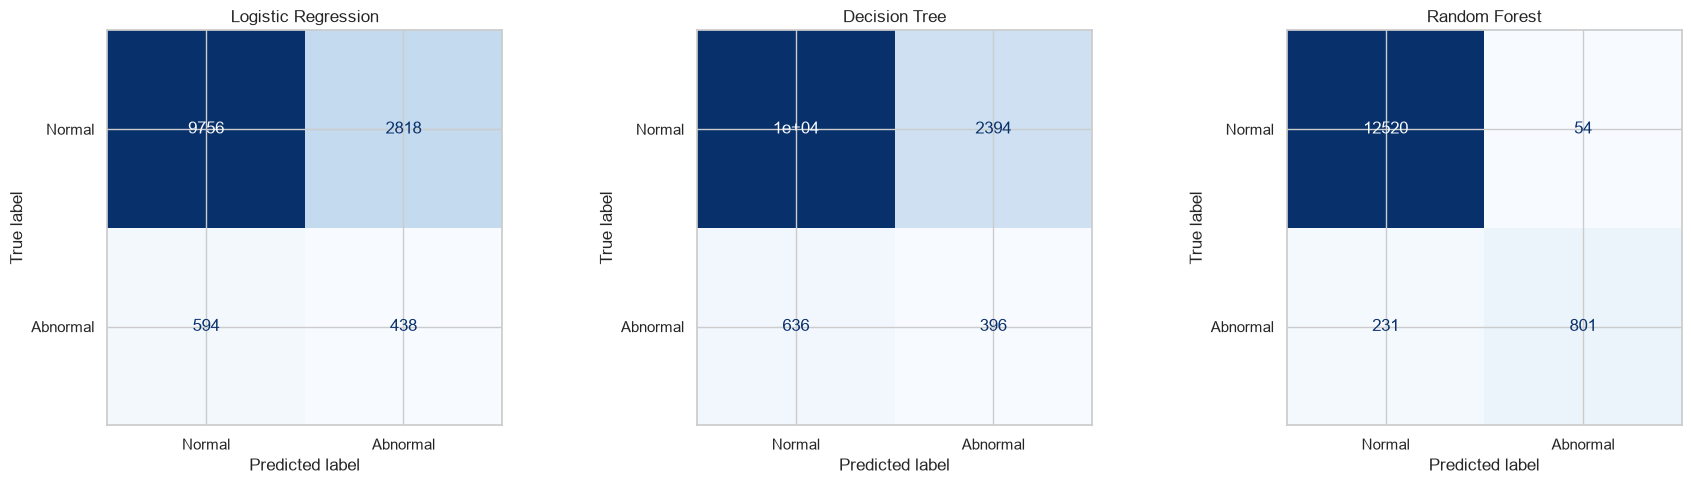

In [22]:
# Plot validation confusion matrices

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    if name == "Logistic Regression":
        predictions = model.predict(X_val_scaled)
    else:
        predictions = model.predict(X_val)

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Abnormal"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [23]:
# Detailed classification reports

for name, model in trained_models.items():

    if name == "Logistic Regression":
        predictions = model.predict(X_val_scaled)
    else:
        predictions = model.predict(X_val)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_val,
            predictions,
            target_names=["Normal", "Abnormal"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      Normal       0.94      0.78      0.85     12574
    Abnormal       0.13      0.42      0.20      1032

    accuracy                           0.75     13606
   macro avg       0.54      0.60      0.53     13606
weighted avg       0.88      0.75      0.80     13606


Decision Tree
              precision    recall  f1-score   support

      Normal       0.94      0.81      0.87     12574
    Abnormal       0.14      0.38      0.21      1032

    accuracy                           0.78     13606
   macro avg       0.54      0.60      0.54     13606
weighted avg       0.88      0.78      0.82     13606


Random Forest
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99     12574
    Abnormal       0.94      0.78      0.85      1032

    accuracy                           0.98     13606
   macro avg       0.96      0.89      0.92     13606
weighted avg       0.98

# 10. Hyperparameter Tuning

Random Forest achieved the best performance among the baseline models.
Therefore, hyperparameter tuning will focus on this classifier.

The optimization process will use stratified group cross-validation
to prevent patient-level data leakage.

In [24]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold

# Training patient groups only
groups_train = groups[train_idx]

# Random Forest estimator
rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
param_distributions = {
    "n_estimators": [100, 150, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

# Group-aware cross-validation
group_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomized search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="average_precision",
    cv=group_cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True
)

# Fit using training data only
random_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation PR-AUC:")
print(random_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10, 'class_weight': 'balanced'}

Best cross-validation PR-AUC:
0.6023958579365895


In [26]:
from IPython.display import display

In [27]:
# Retrieve the best model
best_rf = random_search.best_estimator_

# Predict on validation data
y_val_tuned = best_rf.predict(X_val)
y_val_prob_tuned = best_rf.predict_proba(X_val)[:, 1]

# Calculate evaluation metrics
tuned_results = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_val, y_val_tuned),
    "Precision": precision_score(y_val, y_val_tuned, zero_division=0),
    "Recall": recall_score(y_val, y_val_tuned, zero_division=0),
    "F1-score": f1_score(y_val, y_val_tuned, zero_division=0),
    "PR-AUC": average_precision_score(y_val, y_val_prob_tuned)
}

display(pd.DataFrame([tuned_results]).round(4))

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Tuned Random Forest,0.9688,0.7772,0.8246,0.8002,0.8732


In [28]:
# Compare baseline and tuned Random Forest

comparison = validation_df[
    validation_df["Model"] == "Random Forest"
][["Accuracy", "Precision", "Recall", "F1-score", "PR-AUC"]].copy()

comparison.index = ["Baseline Random Forest"]

tuned_comparison = pd.DataFrame(
    [{
        "Accuracy": tuned_results["Accuracy"],
        "Precision": tuned_results["Precision"],
        "Recall": tuned_results["Recall"],
        "F1-score": tuned_results["F1-score"],
        "PR-AUC": tuned_results["PR-AUC"]
    }],
    index=["Tuned Random Forest"]
)

comparison = pd.concat([comparison, tuned_comparison])

display(comparison.round(4))

,Accuracy,Precision,Recall,F1-score,PR-AUC
Baseline Random Forest,0.9791,0.9368,0.7762,0.8490,0.8660
Tuned Random Forest,0.9688,0.7772,0.8246,0.8002,0.8732


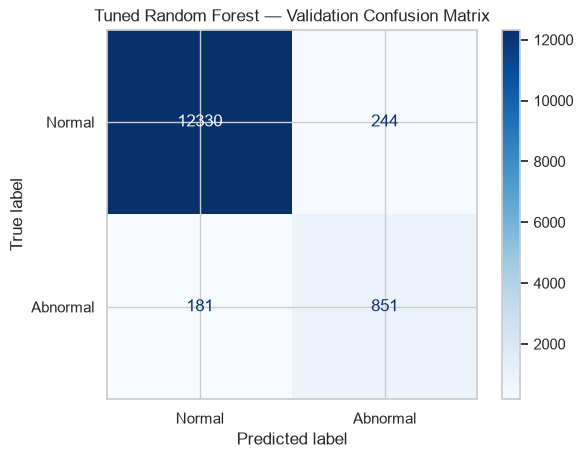

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_tuned,
    labels=[0, 1],
    display_labels=["Normal", "Abnormal"],
    cmap="Blues"
)

plt.title("Tuned Random Forest — Validation Confusion Matrix")
plt.show()

# 11. Classification Threshold Analysis

This section evaluates different classification thresholds
to understand the trade-off between detecting abnormal heartbeats
and generating false positive predictions.

In [30]:
from sklearn.metrics import precision_recall_curve

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

models_to_compare = {
    "Baseline Random Forest": (
        trained_models["Random Forest"],
        X_val
    ),
    "Tuned Random Forest": (
        best_rf,
        X_val
    )
}

for model_name, (model, features) in models_to_compare.items():

    probabilities = model.predict_proba(features)[:, 1]

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Model,Threshold,Precision,Recall,F1-score
0,Baseline Random Forest,0.2,0.1516,0.9244,0.2605
1,Baseline Random Forest,0.3,0.3302,0.8924,0.4821
2,Baseline Random Forest,0.4,0.6950,0.8391,0.7603
3,Baseline Random Forest,0.5,0.9316,0.7781,0.8479
4,Baseline Random Forest,0.6,0.9838,0.7083,0.8237
5,Baseline Random Forest,0.7,0.9947,0.5426,0.7022
6,Baseline Random Forest,0.8,0.9938,0.3120,0.4749
7,Tuned Random Forest,0.2,0.1255,0.9816,0.2226
8,Tuned Random Forest,0.3,0.2157,0.9167,0.3492
9,Tuned Random Forest,0.4,0.4193,0.8740,0.5668


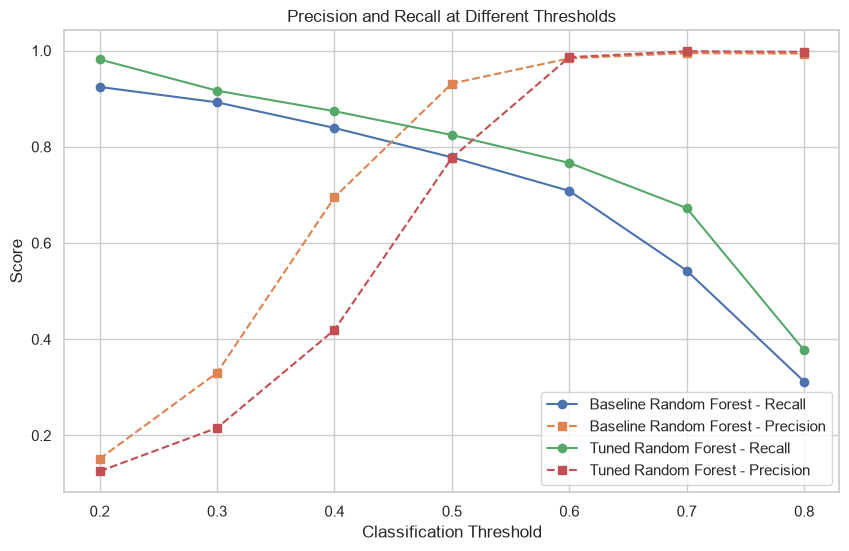

In [31]:
plt.figure(figsize=(10, 6))

for model_name in threshold_df["Model"].unique():

    subset = threshold_df[
        threshold_df["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["Recall"],
        marker="o",
        label=f"{model_name} - Recall"
    )

    plt.plot(
        subset["Threshold"],
        subset["Precision"],
        marker="s",
        linestyle="--",
        label=f"{model_name} - Precision"
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Thresholds")
plt.legend()
plt.grid(True)
plt.show()

# 12. Final Model Evaluation

The tuned Random Forest classifier was selected based on its
validation F1-score.

A classification threshold of 0.6 was selected to balance
precision and recall.

The final model is evaluated using the independent test set,
which was not used during training or model selection.

In [33]:
# Final model and classification threshold

FINAL_MODEL = best_rf
FINAL_THRESHOLD = 0.60

# Predict probabilities on the test set
y_test_prob = FINAL_MODEL.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (
    y_test_prob >= FINAL_THRESHOLD
).astype(int)

print("Final model:", "Tuned Random Forest")
print("Classification threshold:", FINAL_THRESHOLD)
print("Test samples:", len(y_test))

Final model: Tuned Random Forest
Classification threshold: 0.6
Test samples: 13869


In [34]:
# Final test evaluation

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_test_pred, zero_division=0),
    "PR-AUC": average_precision_score(y_test, y_test_prob)
}

final_results = pd.DataFrame(
    [final_metrics],
    index=["Tuned Random Forest"]
)

display(final_results.round(4))

,Accuracy,Precision,Recall,F1-score,PR-AUC
Tuned Random Forest,0.9512,0.7074,0.6918,0.6995,0.7696


In [35]:
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Normal", "Abnormal"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97     12730
    Abnormal       0.71      0.69      0.70      1139

    accuracy                           0.95     13869
   macro avg       0.84      0.83      0.84     13869
weighted avg       0.95      0.95      0.95     13869



In [36]:
# Save final evaluation results

final_results.to_csv(
    REPORTS_DIR / "final_test_metrics.csv"
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=["Actual_Normal", "Actual_Abnormal"],
    columns=["Predicted_Normal", "Predicted_Abnormal"]
).to_csv(
    REPORTS_DIR / "final_confusion_matrix.csv"
)

print("Final evaluation reports saved.")

Final evaluation reports saved.


# 13. Model Persistence

The final tuned Random Forest model is saved to allow
reproducibility and future predictions without retraining.

In [37]:
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the final model
joblib.dump(
    best_rf,
    MODEL_DIR / "final_random_forest.joblib"
)

# Save model configuration
model_config = {
    "model": "Random Forest",
    "threshold": 0.60,
    "parameters": random_search.best_params_,
    "features": WINDOW_SIZE,
    "sampling_frequency": FS,
    "classification": {
        "0": "Normal",
        "1": "Abnormal"
    }
}

with open(MODEL_DIR / "model_config.json", "w") as file:
    json.dump(model_config, file, indent=4)

print("Final model saved successfully.")

Final model saved successfully.


In [38]:
final_results.to_csv(
    REPORTS_DIR / "final_test_metrics.csv",
    index=True
)

print("Final metrics saved.")

Final metrics saved.
